# Variational Autoencoder (VAE)

_[based on our assignment from YSDA [DeepCVG course](https://github.com/yandexdataschool/deep_vision_and_graphics/tree/fall23); materials by Victor Yurchenko]_

**TL;DR this task** will walk involve you implementing your variational autoencoder with normal latent variables - just the basic variety - to model celebrity faces from CelebA dataset.

![img](https://miro.medium.com/v2/resize:fit:1400/0*39kjKwCtVjhrvsQ7.png)


Source links (in addition to our materials):
* Original paper http://arxiv.org/abs/1312.6114
* Helpful videos explaining the topic
   * https://www.youtube.com/watch?v=P78QYjWh5sM     
   * http://videolectures.net/deeplearning2015_courville_autoencoder_extension/?q=aaron%20courville

### Download data

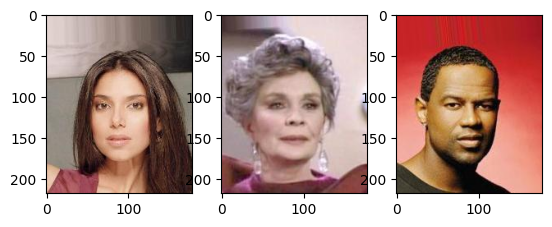

In [ ]:
!wget https://raw.githubusercontent.com/yandexdataschool/Practical_DL/refs/heads/fall24/week09_generative/yfile.py -O yfile.py
from yfile import download_from_yadisk
import os

TARGET_DIR = '.'
FILENAME = "celeba.zip"

if not os.path.exists(os.path.join(TARGET_DIR, FILENAME)):
  print("Downloading...") # this will download 1.4 gb file, downloading will take some time (8-10 minutes)
  download_from_yadisk(short_url='https://disk.yandex.ru/d/QErNx-MoC-2Y6Q',
                        filename=FILENAME, target_dir=TARGET_DIR)
  # alternative manual download:  https://drive.google.com/file/d/1lwn2JMwWNGloGvyzKUOcewT8JqP1ICoW

  print("Extracting...")
  !unzip celeba.zip  # extract images; you don't need to run it every time
  print("Done!")
else:
  print("Found previously downloaded data!")

filesize = os.path.getsize(os.path.join(TARGET_DIR, FILENAME))
assert filesize > 2 ** 30, "{filesize} GiB is too small, something wrong with downloading - please clean up and re-download"

import matplotlib.pyplot as plt
plt.subplot(131); plt.imshow(plt.imread("celeba/celeba/img_align_celeba/100019.jpg"))
plt.subplot(132); plt.imshow(plt.imread("celeba/celeba/img_align_celeba/000084.jpg"))
plt.subplot(133); plt.imshow(plt.imread("celeba/celeba/img_align_celeba/148483.jpg"))

## Prepare the data

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch import optim
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision.utils import make_grid

device = torch.device("cuda" if torch.cuda.is_available() else 'cpu')

In [ ]:
# Note that for simplicity we reduce the number of channels to 1
# But if you want to be hardcore feel free to comment-out .Grayscale below :)


class CropCelebA64:  # custom preprocessing for CelebA
    def __call__(self, pic):
        new_pic = pic.crop((15, 40, 178 - 15, 218 - 30))
        return new_pic
    def __repr__(self):
        return self.__class__.__name__ + '()'


train_dataset = torchvision.datasets.CelebA(
    root='celeba',
    split='train',
    transform=torchvision.transforms.Compose([
        CropCelebA64(),
        torchvision.transforms.Resize(64),
        torchvision.transforms.RandomHorizontalFlip(),
        torchvision.transforms.ToTensor(),

        torchvision.transforms.Grayscale()
    ]),
    #download=True,   # in case of problems with downloading from gdrive above
)

validation_dataset = torchvision.datasets.CelebA(
    root='celeba',
    split='valid',
    transform=torchvision.transforms.Compose([
        CropCelebA64(),
        torchvision.transforms.Resize(64),
        torchvision.transforms.ToTensor(),

        torchvision.transforms.Grayscale()
    ]),
)

In [ ]:
# Hold out the first 10k images for evaluation
num_images = 10000
real_images_tensor = torch.stack([train_dataset[i][0] for i in range(num_images)], dim=0)
real_images = real_images_tensor.data.numpy().transpose([0, 2, 3, 1])
np.savez("real.npz", Pictures=real_images.reshape(num_images, 64 * 64 * 1))

In [ ]:
BATCH_SIZE = 64  # feel free to alter after initial tuning

# you may find useful parameters `num_workers` and `pin_memory`
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE)
print("Image batch shape:", next(iter(train_loader))[0].shape)


Image batch shape: torch.Size([64, 1, 64, 64])


# Autoencoder

Why to use all this complicated formulaes and regularizations, what is the need for variational inference? To analyze the difference, let's first train just an autoencoder on the data:

In [ ]:
dimZ = 100  # Considering face reconstruction task, which size of representation seems reasonable?

# Define the decoder and encoder as networks with one hidden fc-layer
# (that means you will have 2 fc layers in each net)
# Use ReLU for hidden layers' activations
# GlorotUniform initialization for W
# Zero initialization for biases
# It's also convenient to put sigmoid activation on output layer to get nice normalized pics


class Autoencoder(nn.Module):

    def __init__(self):
        super(Autoencoder, self).__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 64, 512),
            nn.ReLU(),
            nn.Linear(512, dimZ)
        )

        self.decoder = nn.Sequential(
            nn.Linear(dimZ, 512),
            nn.ReLU(),
            nn.Linear(512, 64 * 64),
            nn.Sigmoid(),
            nn.Unflatten(1, (1, 64, 64))
        )

        for layer in self.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        latent_code = self.encoder(x)
        reconstruction = self.decoder(latent_code)



        return reconstruction, latent_code

In [ ]:
# Create MSE loss function
criterion = torch.nn.MSELoss()

autoencoder = Autoencoder().to(device)

# Use Adam optimizer
optimizer = optim.Adam(autoencoder.parameters())

Epoch 1: train=0.01115, val=0.00729
Epoch 2: train=0.00662, val=0.00617
Epoch 3: train=0.00592, val=0.00591


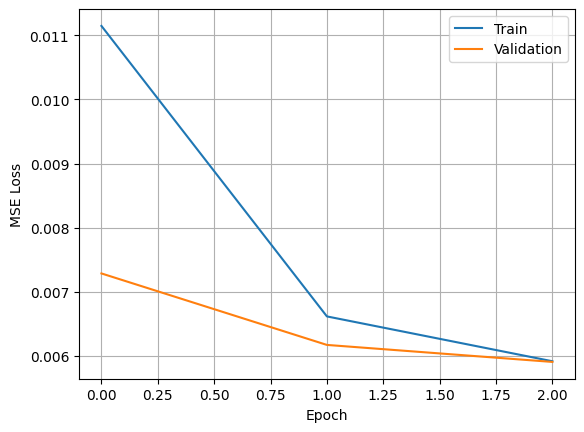

In [16]:
# Train your autoencoder
# Visualize progress in reconstruction and loss decay

num_epochs = 3
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    autoencoder.train()
    train_loss = 0.0

    for images, _ in train_loader:
        images = images.to(device)

        optimizer.zero_grad()
        reconstruction, z = autoencoder(images)
        loss = criterion(reconstruction, images)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)

    autoencoder.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            reconstruction, _ = autoencoder(images)
            loss = criterion(reconstruction, images)
            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_loader.dataset)
    val_losses.append(val_loss)

    print(f"Epoch {epoch + 1}: train={train_loss:.5f}, val={val_loss:.5f}")

plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()


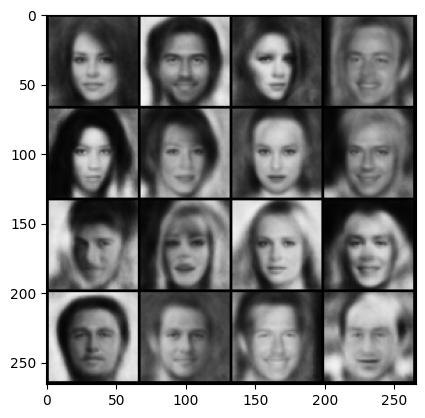

In [17]:
# Examine the reconstructions
from itertools import islice

images, _ = list(islice(val_loader, 1))[0]
reconstruction, latent_code = autoencoder(images.to(device))

reconstruction = reconstruction[:16].cpu()
plt.imshow(make_grid(reconstruction, nrow=4).permute(1, 2, 0))

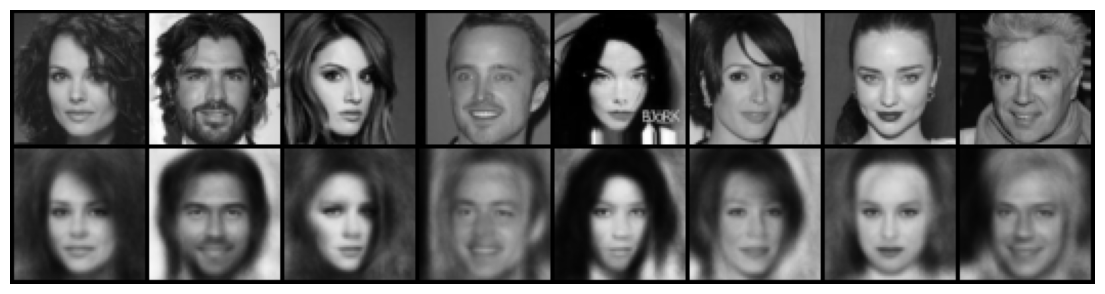

In [21]:
autoencoder.eval()

images, _ = next(iter(val_loader))
images = images[:8].to(device)

with torch.no_grad():
    reconstruction, z = autoencoder(images)

comparison = torch.cat([images.cpu(), reconstruction.cpu()])
grid = make_grid(comparison, nrow=8)

plt.figure(figsize=(14, 4))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.show()


Reconstruction is not bad, right?  Okay, it very well might be bad, but it should at least be a blurry image.

# Sampling

Let's now sample several latent vectors and perform inference from $z$, reconstruct an image given some random $z$ representations.

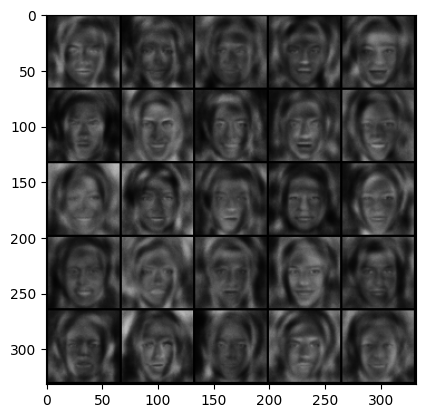

In [22]:
z = torch.randn(25, dimZ) * 0.5
reconstruction = autoencoder.decoder(z.to(device)).clamp(0, 1)

plt.imshow(make_grid(reconstruction.cpu(), nrow=5).permute(1, 2, 0))

So, if we sample $z$ from normal, whould we eventually generate all possible faces? What do you think?

# Variational Autoencoder

Bayesian approach in deep learning considers everything in terms of distributions. Now our encoder generates not just a vector $z$ but posterior ditribution $q(z|x)$. In our case distribution $q$ is Gaussian distibution $N(\mu, \sigma)$ with parameters $\mu$, $\sigma$. Technically, the first difference is that you need to split bottleneck layer in two. One dense layer will generate vector $\mu$, and another will generate vector $\sigma$. Reparametrization trick should be implemented using the **gaussian_sampler** layer, that generates random vetor $\epsilon$ and returns $\mu+\sigma\epsilon \sim N(\mu, \sigma)$ .

Since our decoder is also a function that generates distribution, we need to do the same splitting for output layer. When testing the model we will look only on mean values, so one of the output will be actual autoencoder output.

In this homework we only ask for implementation of the simplest version of VAE - one $z$ sample per input. You can consider to sample several outputs from one input and average them.

In [23]:
# to compare with conventional AE, keep these hyperparameters
# or change them for the values that you used before
dimZ = 100

# define the network
# you can start from https://github.com/pytorch/examples/blob/master/vae/main.py
# or Theano-based examples here https://github.com/Lasagne/Recipes/blob/master/examples/variational_autoencoder/variational_autoencoder.py
# and here https://github.com/y0ast/Variational-Autoencoder/blob/master/VAE.py
# but remember that this is not your ground truth since the data is not MNIST


class VAE(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 64, 512),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(512, dimZ)
        self.fc_logsigma = nn.Linear(512, dimZ)

        self.decoder = nn.Sequential(
            nn.Linear(dimZ, 512),
            nn.ReLU()
        )

        self.decoder_mu = nn.Linear(512, 64 * 64)
        self.decoder_logsigma = nn.Linear(512, 64 * 64)

        for layer in self.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)
    def gaussian_sampler(self, mu, logsigma):
        noise = torch.randn_like(mu)
        return noise * logsigma.exp() + mu

    def forward(self, x):
        h = self.encoder(x)

        mu_z = self.fc_mu(h)
        logsigma_z = self.fc_logsigma(h)
        z = self.gaussian_sampler(mu_z, logsigma_z)

        h = self.decoder(z)

        mu_gen = torch.sigmoid(self.decoder_mu(h))
        logsigma_gen = self.decoder_logsigma(h)

        mu_gen = mu_gen.reshape(-1, 1, 64, 64)
        logsigma_gen = logsigma_gen.reshape(-1, 1, 64, 64)

        return mu_gen, logsigma_gen, mu_z, logsigma_z


And the last, but not least! Place in the code where the most of the formulaes goes to - optimization objective. The objective for VAE has it's own name - variational lowerbound. And as for any lowerbound our intention is to maximize it. Here it is (for one sample $z$ per input $x$):

$$\mathcal{L} = -D_{KL}(q_{\phi}(z|x)||p(z)) + \log p_{\theta}(x|z) \to max$$

Your next task is to implement two functions that compute KL-divergence and the second term - log-likelihood of an output. Here is some necessary math for your convenience:

$$D_{KL} = -\frac{1}{2}\sum_{i=1}^{dimZ}(1+log(\sigma_i^2)-\mu_i^2-\sigma_i^2)$$
$$\log p_{\theta}(x|z) = \sum_{i=1}^{dimX}\log p_{\theta}(x_i|z)=\sum_{i=1}^{dimX} \log \Big( \frac{1}{\sigma_i\sqrt{2\pi}}e^{-\frac{(\mu_i-x)^2}{2\sigma_i^2}} \Big)=...$$

Don't forget in the code that you are using $\log\sigma$ as variable. Explain, why not $\sigma$?

In [29]:
import math
def KL_divergence(mu, logsigma):
    kl = 0.5 * (mu**2 + torch.exp(2 * logsigma) - 1 - 2 * logsigma)
    return kl.sum(dim=1).mean()


def log_likelihood(x, mu, logsigma):
    log_prob = -0.5 * (
        (x - mu)**2 * torch.exp(-2 * logsigma)
        + 2 * logsigma
        + math.log(2 * math.pi)
    )
    return log_prob.flatten(1).sum(dim=1).mean()


def loss_vae(x, mu_gen, logsigma_gen, mu_z, logsigma_z):
    kl = KL_divergence(mu_z, logsigma_z)
    reconstruction = log_likelihood(x, mu_gen, logsigma_gen)
    return kl - reconstruction

And train the model:

Epoch 1: train=-1926.25, val=-2890.62
Epoch 2: train=-3387.93, val=-3773.33
Epoch 3: train=-3899.71, val=-4071.42


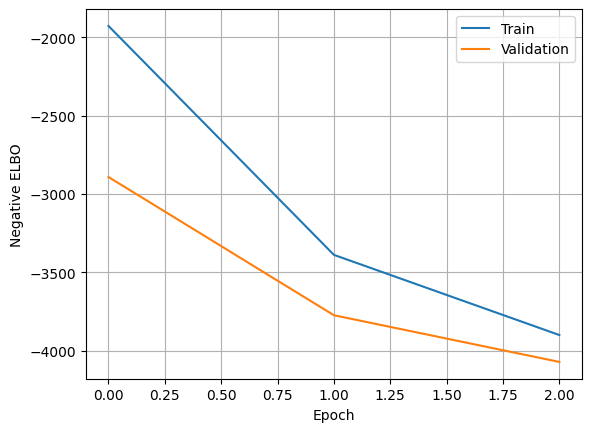

In [32]:
# train your variational autoencoder
# visualize progress in reconstruction and loss decay

vae = VAE().to(device)
optimizer_vae = optim.Adam(vae.parameters(), lr=1e-4)

num_epochs = 3
vae_train_losses = []
vae_val_losses = []

for epoch in range(num_epochs):
    vae.train()
    train_loss = 0.0

    for images, _ in train_loader:
        images = images.to(device)

        optimizer_vae.zero_grad()

        mu_gen, logsigma_gen, mu_z, logsigma_z = vae(images)
        loss = loss_vae(images, mu_gen, logsigma_gen, mu_z, logsigma_z)

        loss.backward()
        optimizer_vae.step()

        train_loss += loss.item() * images.size(0)

    train_loss /= len(train_loader.dataset)
    vae_train_losses.append(train_loss)

    vae.eval()
    val_loss = 0.0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)

            mu_gen, logsigma_gen, mu_z, logsigma_z = vae(images)
            loss = loss_vae(images, mu_gen, logsigma_gen, mu_z, logsigma_z)

            val_loss += loss.item() * images.size(0)

    val_loss /= len(val_loader.dataset)
    vae_val_losses.append(val_loss)

    print(f"Epoch {epoch + 1}: train={train_loss:.2f}, val={val_loss:.2f}")

plt.plot(vae_train_losses, label="Train")
plt.plot(vae_val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Negative ELBO")
plt.legend()
plt.grid(True)
plt.show()


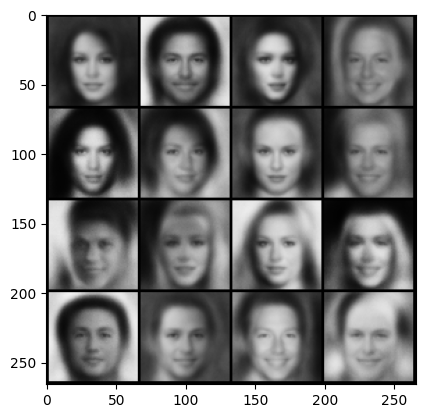

In [33]:
images, _ = list(islice(val_loader, 1))[0]
mu_gen, _, _, _ = vae(images.to(device))
reconstruction = mu_gen[:16].cpu().clamp(0, 1)

plt.imshow(make_grid(reconstruction, nrow=4).permute(1, 2, 0))

And finally sample from VAE.

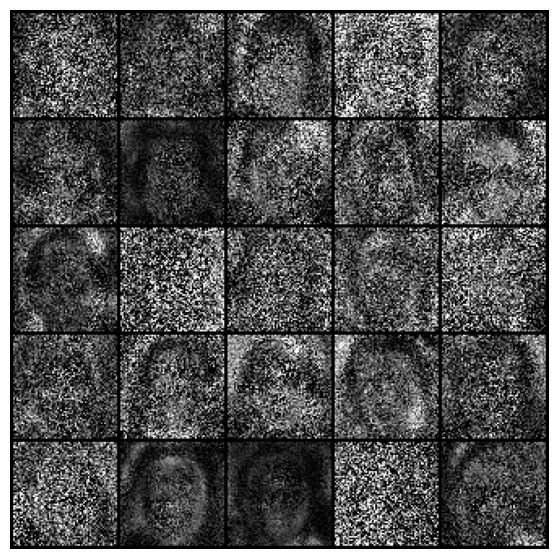

In [35]:
# Sample some images from the learned distribution
# 1) Sample z ~ N(0,1)
# 2) Sample from N(decoder_mu(z), decoder_sigma(z))

vae.eval()

with torch.no_grad():
    z = torch.randn(25, dimZ, device=device)
    h = vae.decoder(z)

    mu = torch.sigmoid(vae.decoder_mu(h))
    logsigma = vae.decoder_logsigma(h)

    samples = mu + torch.randn_like(mu) * logsigma.exp()
    samples = samples.reshape(25, 1, 64, 64).clamp(0, 1)

grid = make_grid(samples.cpu(), nrow=5)

plt.figure(figsize=(7, 7))
plt.imshow(grid[0], cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()


Sigma min: 0.0323
Sigma median: 0.2422
Sigma max: 0.9799


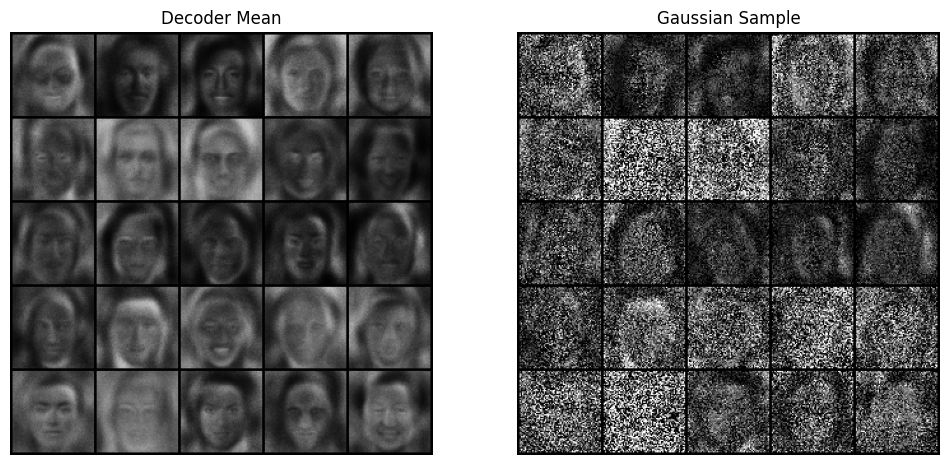

In [36]:

vae.eval()

with torch.no_grad():
    z = torch.randn(25, dimZ, device=device)
    h = vae.decoder(z)

    mu = torch.sigmoid(vae.decoder_mu(h))
    sigma = vae.decoder_logsigma(h).exp()

    mean_images = mu.reshape(25, 1, 64, 64)
    sampled_images = (mu + sigma * torch.randn_like(mu))
    sampled_images = sampled_images.reshape(25, 1, 64, 64).clamp(0, 1)

    print(f"Sigma min: {sigma.min().item():.4f}")
    print(f"Sigma median: {sigma.median().item():.4f}")
    print(f"Sigma max: {sigma.max().item():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(make_grid(mean_images.cpu(), nrow=5)[0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Decoder Mean")

axes[1].imshow(make_grid(sampled_images.cpu(), nrow=5)[0], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Gaussian Sample")

for ax in axes:
    ax.axis("off")

plt.show()


The decoder mean produces blurry but recognizable faces. Sampling each pixel adds noticeable noise (median predicted sigma: 0.2422), so the sampled images look much worse.

Even if in practice you do not see the much difference between AE and VAE, or VAE is even worse, the little bayesian inside you should be jumping for joy right now.

In VAE you can truly sample from image distribution $p(x)$, while in AE there is no easy and correct way to do it.

# If you made it here - Congrats! (and here's an optional bonus task)

If you managed to tune your autoencoders to converge and learn something about the world, now it's time to make fun out of it. As you may have noticed, there are face attributes in dataset. We're interesting in "Smiling" column (index 31 of the attribute vector), but feel free to try others as well! Here is the first task:

1) Extract the "Smilling" attribute and create a two sets of images: 10 smiling faces and 10 non-smiling ones.

2) Compute latent representations for each image in "smiling" set and average those latent vectors. Do the same for "non-smiling" set. You have found **"vector representation"** of the "smile" and "no smile" attribute.

3) Compute the difference: "smile" vector minus "non-smile" vector.

3) Now check if **"feature arithmetics"** works. Sample a face without smile, encode it and add the diff from p. 3. Check if it works with both AE and VAE.

In [37]:

smiling = []
not_smiling = []

for i in range(len(validation_dataset)):
    image, attrs = validation_dataset[i]

    if attrs[31].item() == 1 and len(smiling) < 10:
        smiling.append(image)

    if attrs[31].item() == 0 and len(not_smiling) < 10:
        not_smiling.append(image)

    if len(smiling) == 10 and len(not_smiling) == 10:
        break

smiling = torch.stack(smiling).to(device)
not_smiling = torch.stack(not_smiling).to(device)

print("Smiling:", smiling.shape)
print("Not smiling:", not_smiling.shape)


Smiling: torch.Size([10, 1, 64, 64])
Not smiling: torch.Size([10, 1, 64, 64])


In [38]:

autoencoder.eval()

with torch.no_grad():
    z_smile_ae = autoencoder.encoder(smiling)
    z_neutral_ae = autoencoder.encoder(not_smiling)

    smile_direction_ae = z_smile_ae.mean(dim=0) - z_neutral_ae.mean(dim=0)

print("AE smile direction:", smile_direction_ae.shape)


AE smile direction: torch.Size([100])


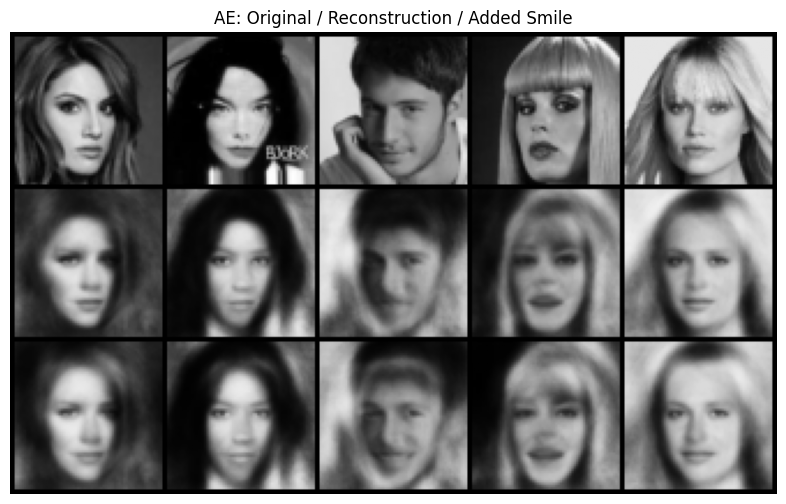

In [39]:

alpha = 1.0

with torch.no_grad():
    z = autoencoder.encoder(not_smiling[:5])

    ae_before = autoencoder.decoder(z)
    ae_after = autoencoder.decoder(z + alpha * smile_direction_ae)

images = torch.cat([
    not_smiling[:5].cpu(),
    ae_before.cpu(),
    ae_after.cpu()
])

plt.figure(figsize=(10, 6))
plt.imshow(make_grid(images, nrow=5)[0], cmap="gray", vmin=0, vmax=1)
plt.title("AE: Original / Reconstruction / Added Smile")
plt.axis("off")
plt.show()


In [40]:

vae.eval()

with torch.no_grad():
    mu_smile = vae.fc_mu(vae.encoder(smiling))
    mu_neutral = vae.fc_mu(vae.encoder(not_smiling))

    smile_direction_vae = mu_smile.mean(dim=0) - mu_neutral.mean(dim=0)

print("VAE smile direction:", smile_direction_vae.shape)


VAE smile direction: torch.Size([100])


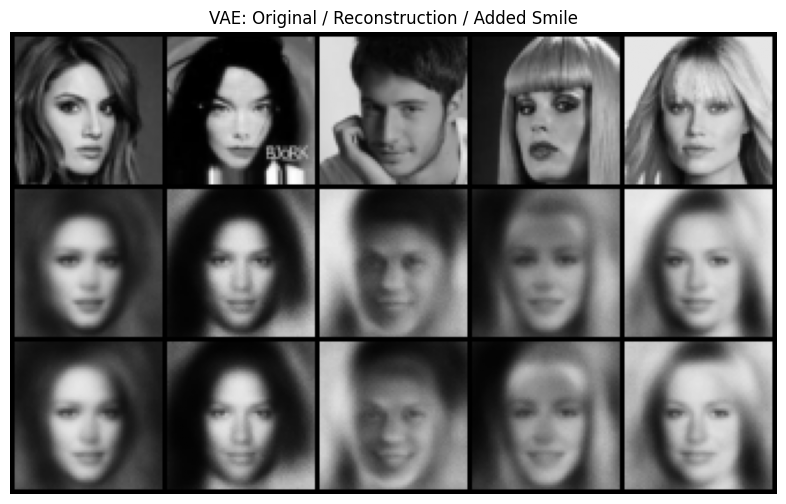

In [41]:

with torch.no_grad():
    z = vae.fc_mu(vae.encoder(not_smiling[:5]))

    h_before = vae.decoder(z)
    h_after = vae.decoder(z + alpha * smile_direction_vae)

    vae_before = torch.sigmoid(vae.decoder_mu(h_before))
    vae_after = torch.sigmoid(vae.decoder_mu(h_after))

    vae_before = vae_before.reshape(-1, 1, 64, 64)
    vae_after = vae_after.reshape(-1, 1, 64, 64)

images = torch.cat([
    not_smiling[:5].cpu(),
    vae_before.cpu(),
    vae_after.cpu()
])

plt.figure(figsize=(10, 6))
plt.imshow(make_grid(images, nrow=5)[0], cmap="gray", vmin=0, vmax=1)
plt.title("VAE: Original / Reconstruction / Added Smile")
plt.axis("off")
plt.show()



We computed a smile direction using the difference between the average latent representations of smiling and non-smiling faces. Adding this direction made several faces appear to smile more, especially in the last three examples. Both AE and VAE showed this effect, although the VAE results were blurrier. Some other facial features also changed, so the learned direction is not perfectly disentangled.